In [ ]:
!pip install mne

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 25.2 MB/s  0:00:00
  Attempting uninstall: decorator
    Found existing installation: decorator 4.4.2
    Uninstalling decorator-4.4.2:
      Successfully uninstalled decorator-4.4.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [mne]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [ ]:
import mne
import numpy as np
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader, TensorDataset
import pandas as pd
import torch.nn.functional as F
import torch
import torch.nn as nn
import glob
import os
import torch.optim as optim
from tqdm import tqdm
from sklearn.model_selection import train_test_split
import torchvision.models as models
from sklearn.metrics import precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.model_selection import GroupShuffleSplit
import librosa

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
REPO_ROOT = Path(
    "/content/drive/MyDrive/EEG_Project_Github/eeg-brain-age"
).resolve()

if not REPO_ROOT.is_dir():
    raise FileNotFoundError(
        f"Repository directory not found: {REPO_ROOT}\n"
        "Check that Google Drive is mounted and the path is correct."
    )

SRC_DIR = REPO_ROOT / "src"

if not SRC_DIR.is_dir():
    raise FileNotFoundError(
        f"Source directory not found: {SRC_DIR}"
    )

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

# Dataset path: change this when using another environment.
base_dir = Path(
    "/content/drive/MyDrive/EEG_Project/EEG_Project"
)

if not base_dir.is_dir():
    raise FileNotFoundError(
        f"EEG dataset directory not found: {base_dir}"
    )



from eeg_brain_age.data import (
    create_age_labels,
    discover_eeg_files,
    find_common_channels,
    build_samples,
)
from eeg_brain_age.splits import split_train_validation_test
from eeg_brain_age.dataloaders import create_dataloaders
from eeg_brain_age.models import CNNLSTMModel
from eeg_brain_age.training import compute_class_weights, train_model
from eeg_brain_age.evaluation import evaluate_full
from eeg_brain_age.visualization import (
    plot_training_curves,
    plot_confusion_matrix,
)


file_paths = discover_eeg_files(str(base_dir))

print("Repository:", REPO_ROOT)
print("Dataset directory:", base_dir)
print("EEG files discovered:", len(file_paths))


Repository: /content/drive/MyDrive/EEG_Project_Github/eeg-brain-age
EEG files discovered: 202


##Loading the meta data file

In [ ]:
metadata_path = Path(
    "/content/drive/MyDrive/EEG_Project/"
    "META_File_IDs_Age_Gender_Education_Drug_Smoke_SKID_LEMON.csv"
)

if not metadata_path.is_file():
    raise FileNotFoundError(
        f"Metadata file not found: {metadata_path}"
    )

label_df = pd.read_csv(metadata_path)
label_df = label_df["Age"]

label_df.head(10)


,Age
0,20-25
1,20-25
2,25-30
3,20-25
4,20-25
5,25-30
6,25-30
7,60-65
8,25-30
9,25-30


In [ ]:
label_df.describe()

,Age
count,228
unique,9
top,20-25
freq,79


In [ ]:
label_df.unique()

array(['20-25', '25-30', '60-65', '30-35', '70-75', '65-70', '75-80',
       '55-60', '35-40'], dtype=object)

In [ ]:
metadata = pd.read_csv(metadata_path)

metadata, age_to_label, label_to_age, label_map = create_age_labels(
    metadata
)

print(label_map)

class_counts = metadata["Label"].value_counts()
print("Number of samples per class:", class_counts)

{'sub-032311': 0, 'sub-032309': 0, 'sub-032382': 1, 'sub-032302': 0, 'sub-032315': 0, 'sub-032314': 1, 'sub-032316': 1, 'sub-032383': 2, 'sub-032307': 1, 'sub-032310': 1, 'sub-032312': 0, 'sub-032317': 0, 'sub-032404': 0, 'sub-032318': 2, 'sub-032319': 0, 'sub-032386': 0, 'sub-032320': 1, 'sub-032321': 3, 'sub-032322': 0, 'sub-032394': 0, 'sub-032324': 0, 'sub-032323': 0, 'sub-032528': 0, 'sub-032325': 0, 'sub-032313': 0, 'sub-032405': 1, 'sub-032384': 1, 'sub-032407': 0, 'sub-032327': 1, 'sub-032414': 0, 'sub-032418': 0, 'sub-032326': 1, 'sub-032415': 2, 'sub-032332': 0, 'sub-032331': 4, 'sub-032305': 5, 'sub-032308': 2, 'sub-032428': 4, 'sub-032333': 4, 'sub-032430': 5, 'sub-032301': 5, 'sub-032303': 5, 'sub-032336': 5, 'sub-032329': 5, 'sub-032431': 4, 'sub-032335': 2, 'sub-032337': 5, 'sub-032339': 6, 'sub-032306': 5, 'sub-032338': 5, 'sub-032340': 5, 'sub-032341': 4, 'sub-032442': 4, 'sub-032347': 6, 'sub-032444': 3, 'sub-032346': 0, 'sub-032350': 1, 'sub-032351': 0, 'sub-032348':

In [ ]:
# Invert the mapping: number → age range string
label_to_age = {v: k for k, v in age_to_label.items()}

print("=== Label → Age Range ===")
for label in sorted(label_to_age.keys()):
    count = (metadata['Label'] == label).sum()
    print(f"  Label {label} → {label_to_age[label]:10s}  ({count} subjects)")

=== Label → Age Range ===
  Label 0 → 20-25       (79 subjects)
  Label 1 → 25-30       (61 subjects)
  Label 2 → 60-65       (19 subjects)
  Label 3 → 30-35       (13 subjects)
  Label 4 → 70-75       (22 subjects)
  Label 5 → 65-70       (25 subjects)
  Label 6 → 75-80       (4 subjects)
  Label 7 → 55-60       (4 subjects)
  Label 8 → 35-40       (1 subjects)


In [ ]:
all_subject_ids = np.array([
    os.path.basename(os.path.dirname(fp)) for fp in file_paths
])
unique_subjects = np.unique(all_subject_ids)
labels_per_subject = np.array([label_map[s] for s in unique_subjects])

=== Class Distribution ===
  Class 0: 71 subjects
  Class 1: 54 subjects
  Class 2: 17 subjects
  Class 3: 11 subjects
  Class 4: 19 subjects
  Class 5: 23 subjects
  Class 6: 3 subjects
  Class 7: 3 subjects
  Class 8: 1 subjects

Total subjects: 202
Total classes:  9
Min class size: 1
Max class size: 71


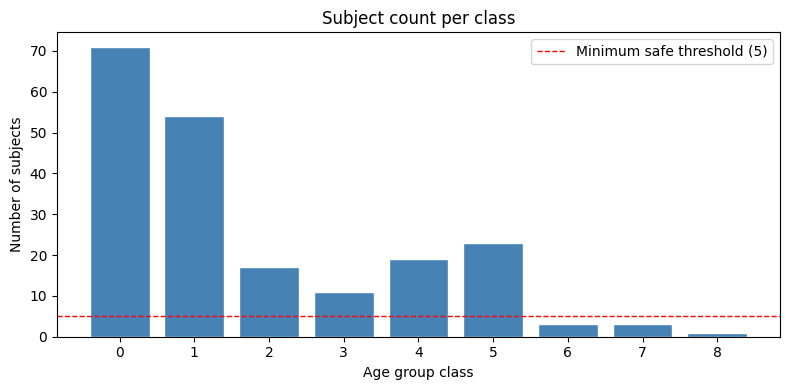

In [ ]:
print("=== Class Distribution ===")
counts = Counter(labels_per_subject)
for label, count in sorted(counts.items()):
    print(f"  Class {label}: {count} subjects")

print(f"\nTotal subjects: {len(unique_subjects)}")
print(f"Total classes:  {len(counts)}")
print(f"Min class size: {min(counts.values())}")
print(f"Max class size: {max(counts.values())}")

# ── visual ──
plt.figure(figsize=(8, 4))
labels_sorted = sorted(counts.keys())
values = [counts[l] for l in labels_sorted]
plt.bar(labels_sorted, values, color='steelblue', edgecolor='white')
plt.axhline(y=5, color='red', linestyle='--', linewidth=1, label='Minimum safe threshold (5)')
plt.xlabel("Age group class")
plt.ylabel("Number of subjects")
plt.title("Subject count per class")
plt.xticks(labels_sorted)
plt.legend()
plt.tight_layout()
plt.show()

##Reading the EEG data and svaing the channel names

In [ ]:
import warnings

warnings.filterwarnings("ignore", category=RuntimeWarning)
mne.set_log_level("ERROR")

In [ ]:
print("Number of EEG files:", len(file_paths))
print("First few EEG files:")
for filepath in file_paths[:5]:
    print(filepath)

Number of EEG files: 202
First few EEG files:
/content/drive/MyDrive/EEG_Project/EEG_Project/sub-032518/sub-032518_EC.set
/content/drive/MyDrive/EEG_Project/EEG_Project/sub-032521/sub-032521_EC.set
/content/drive/MyDrive/EEG_Project/EEG_Project/sub-032524/sub-032524_EC.set
/content/drive/MyDrive/EEG_Project/EEG_Project/sub-032517/sub-032517_EC.set
/content/drive/MyDrive/EEG_Project/EEG_Project/sub-032516/sub-032516_EC.set


In [ ]:
common_channels = find_common_channels(file_paths)

print("Number of common EEG channels:", len(common_channels))
print("Common channels:", common_channels)

Reading channel names:   0%|          | 0/202 [00:00<?, ?it/s]

Number of common EEG channels: 21
Common channels: ['CP3', 'CP5', 'P4', 'P5', 'Oz', 'P6', 'O2', 'P1', 'F4', 'C2', 'P8', 'PO3', 'PO4', 'AF3', 'P2', 'PO8', 'Pz', 'AF4', 'AF8', 'F1', 'C3']


##Making the data into 2D shape

In [ ]:
sfreq = 250
block_duration = 30
blocks_per_sample = 5

samples = build_samples(
    file_paths=file_paths,
    label_map=label_map,
    sfreq=sfreq,
    block_duration=block_duration,
    blocks_per_sample=blocks_per_sample,
)

print("Number of samples:", len(samples))

Building samples:   0%|          | 0/202 [00:00<?, ?it/s]

Number of samples: 595


##Separating data to train, validation and test

In [ ]:
sample_labels = np.array([
    sample['label']
    for sample in samples
])

sample_subjects = np.array([
    sample['subject_id']
    for sample in samples
])

In [ ]:
train_samples, val_samples, test_samples = split_train_validation_test(
    samples=samples,
    train_temp_size=0.30,
    val_test_size=0.50,
    random_state=42,
)

print("Train samples:", len(train_samples))
print("Validation samples:", len(val_samples))
print("Test samples:", len(test_samples))

Train samples: 415
Validation samples: 88
Test samples: 92


In [ ]:
train_subjects = set(
    sample["subject_id"]
    for sample in train_samples
)

val_subjects = set(
    sample["subject_id"]
    for sample in val_samples
)

test_subjects = set(
    sample["subject_id"]
    for sample in test_samples
)

print("Train ∩ Val  :", len(train_subjects & val_subjects))
print("Train ∩ Test :", len(train_subjects & test_subjects))
print("Val ∩ Test   :", len(val_subjects & test_subjects))

Train ∩ Val  : 0
Train ∩ Test : 0
Val ∩ Test   : 0


In [ ]:
print("Train Samples:", len(train_samples))
print("Val Samples:", len(val_samples))
print("Test Samples:", len(test_samples))

print("Train Subjects:", len(train_subjects))
print("Val Subjects:", len(val_subjects))
print("Test Subjects:", len(test_subjects))

Train Samples: 415
Val Samples: 88
Test Samples: 92
Train Subjects: 141
Val Subjects: 30
Test Subjects: 31


In [ ]:
train_df = pd.DataFrame(train_samples)

subject_dist = (
    train_df[["subject_id", "label"]]
    .drop_duplicates()
    .groupby("label")
    .size()
)

print(subject_dist)

label
0    48
1    42
2    12
3     5
4    12
5    16
6     3
7     2
8     1
dtype: int64


In [ ]:
val_df = pd.DataFrame(val_samples)

subject_dist = (
    val_df[["subject_id", "label"]]
    .drop_duplicates()
    .groupby("label")
    .size()
)

print(subject_dist)

label
0    13
1     6
2     2
3     3
4     3
5     3
dtype: int64


In [ ]:
test_df = pd.DataFrame(test_samples)

subject_dist = (
    test_df[["subject_id", "label"]]
    .drop_duplicates()
    .groupby("label")
    .size()
)

print(subject_dist)

label
0    10
1     6
2     3
3     3
4     4
5     4
7     1
dtype: int64


##Creating dataset and dataloaders

In [ ]:
CACHE_DIR = REPO_ROOT / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("Feature cache directory:", CACHE_DIR)

Feature cache directory: /content/drive/MyDrive/EEG_Project_Github/eeg-brain-age/cache


In [ ]:
train_loader, val_loader, test_loader = create_dataloaders(
    train_samples=train_samples,
    val_samples=val_samples,
    test_samples=test_samples,
    common_channels=common_channels,
    batch_size=32,
    use_cache=True,
    cache_dir=CACHE_DIR,
    num_workers=0,
    pin_memory=True,
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 13
Validation batches: 3
Test batches: 3


In [ ]:
for data, label in train_loader:

    print("Shape of the Data: ", data.shape)
    # print(data)
    print("Data Min:", data.min().item())
    print("Data Max:", data.max().item())
    break

Shape of the Data:  torch.Size([32, 5, 21, 64, 15])
Data Min: -69.89714813232422
Data Max: 0.0


##Defining the model

In [ ]:
model = CNNLSTMModel(
    num_classes=len(label_df.unique()),
    num_channels=len(common_channels),
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

model.to(device)

Device: cuda


CNNLSTMModel(
  (shared_cnn): SharedCNN(
    (conv1): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (bn1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (dropout1): Dropout(p=0.2, inplace=False)
    (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (dropout2): Dropout(p=0.2, inplace=False)
    (flatten): Flatten(start_dim=1, end_dim=-1)
    (fc): Linear(in_features=768, out_features=32, bias=True)
    (bn3): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (lstm): LSTM(672, 32, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=64, out_features=9, bias=True)
)

##Defining the class-weight loss


In [ ]:
class_counts, class_weights = compute_class_weights(
    train_samples=train_samples,
    num_classes=len(label_df.unique()),
)

print("Class counts:", class_counts)
print("Class weights:", class_weights)

Class counts: tensor([48., 42., 12.,  5., 12., 16.,  3.,  2.,  1.])
Class weights: tensor([0.7000, 0.7000, 1.3056, 2.0000, 1.3056, 0.9792, 2.0000, 2.0000, 2.0000])


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class_weights = class_weights.to(device)


criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

##Testing

In [ ]:
import ast
import json
import sys
from pathlib import Path
from importlib import metadata

python_files = list((REPO_ROOT / "src" / "eeg_brain_age").glob("*.py"))
notebook_path = REPO_ROOT / "notebooks" / "brain_age_experiment_refactored.ipynb"

imports = set()

# Imports from Python modules
for path in python_files:
    if path.name == "__init__.py":
        pass

    tree = ast.parse(path.read_text(encoding="utf-8"))

    for node in ast.walk(tree):
        if isinstance(node, ast.Import):
            imports.update(alias.name.split(".")[0] for alias in node.names)
        elif isinstance(node, ast.ImportFrom) and node.module:
            if node.level == 0:
                imports.add(node.module.split(".")[0])

# Imports from notebook code cells
with open(notebook_path, encoding="utf-8") as f:
    notebook = json.load(f)

for cell in notebook["cells"]:
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in ast.walk(tree):
        if isinstance(node, ast.Import):
            imports.update(alias.name.split(".")[0] for alias in node.names)
        elif isinstance(node, ast.ImportFrom) and node.module:
            if node.level == 0:
                imports.add(node.module.split(".")[0])

print("=== Imports found ===")

for name in sorted(imports):
    if name in sys.stdlib_module_names:
        category = "Standard library"
    else:
        category = "Third-party or project module"

    print(f"{name}: {category}")

print("\n=== Installed package versions ===")

# Common mappings between Python import names and pip distribution names
package_map = {
    "sklearn": "scikit-learn",
    "PIL": "Pillow",
    "yaml": "PyYAML",
    "cv2": "opencv-python",
    "mne": "mne",
    "librosa": "librosa",
    "numpy": "numpy",
    "pandas": "pandas",
    "scipy": "scipy",
    "torch": "torch",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
}

for name in sorted(imports):
    if name in sys.stdlib_module_names or name == "eeg_brain_age":
        continue

    package = package_map.get(name, name)

    try:
        print(f"{package}=={metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: version not found")

=== Imports found ===
collections: Standard library
eeg_brain_age: Third-party or project module
glob: Standard library
google: Third-party or project module
inspect: Standard library
librosa: Third-party or project module
matplotlib: Third-party or project module
mne: Third-party or project module
numpy: Third-party or project module
os: Standard library
pandas: Third-party or project module
pathlib: Standard library
seaborn: Third-party or project module
sklearn: Third-party or project module
sys: Standard library
torch: Third-party or project module
torchvision: Third-party or project module
tqdm: Third-party or project module
warnings: Standard library

=== Installed package versions ===
google==3.0.0
librosa==0.11.0
matplotlib==3.10.0
mne==1.13.2
numpy==2.1.3
pandas==2.2.3
seaborn==0.13.2
scikit-learn==1.6.1
torch==2.11.0+cpu
torchvision==0.26.0+cpu
tqdm==4.67.3


In [ ]:

from pathlib import Path

# Root directory of the repository
requirements_path = REPO_ROOT / "requirements.txt"
readme_path = REPO_ROOT / "README.md"

# Avoid silently overwriting existing files
if requirements_path.exists() or readme_path.exists():
    raise FileExistsError(
        "README.md or requirements.txt already exists. "
        "Inspect the existing file before replacing it."
    )

requirements = """# Core scientific computing
numpy>=1.24
pandas>=2.0
scikit-learn>=1.3

# EEG processing and feature extraction
mne>=1.5
librosa>=0.10

# Deep learning
torch>=2.0
torchvision>=0.15

# Visualization and progress bars
matplotlib>=3.7
seaborn>=0.12
tqdm>=4.65
"""

readme = r"""# EEG Brain Age Estimation

A deep learning project for estimating age groups from resting-state EEG
(Electroencephalography) recordings using a CNN-LSTM architecture.

## Overview

This project explores EEG-based age-group classification using the LEMON
dataset. EEG recordings are converted into Mel spectrogram representations,
which are processed by a convolutional neural network and a bidirectional
LSTM.

The task is formulated as classification into nine age-related classes,
following the label mapping defined in the project code.

## Pipeline

1. Load participant metadata and construct age labels.
2. Discover EEG recordings and identify common channels.
3. Divide recordings into fixed-duration EEG blocks.
4. Convert EEG blocks into Mel spectrogram representations.
5. Split samples by participant to avoid subject overlap between data splits.
6. Train a CNN-LSTM classifier.
7. Evaluate the model using classification metrics and confusion matrices.

## Model

The model combines:

- **Shared CNN:** extracts spatial and spectral patterns from EEG
  spectrograms.
- **Bidirectional LSTM:** models relationships across the sequence of EEG
  blocks.
- **Classification layer:** predicts one of the age-related classes.

The exact architecture and hyperparameters are defined in `src/eeg_brain_age/`.

## Repository Structure

```text
eeg-brain-age/
├── README.md
├── requirements.txt
├── .gitignore
├── checkpoints/
├── notebooks/
│   ├── brain_age_experiment.ipynb
│   └── brain_age_experiment_refactored.ipynb
├── reports/
│   └── figures/
└── src/
    └── eeg_brain_age/
        ├── data.py
        ├── dataloaders.py
        ├── dataset.py
        ├── evaluation.py
        ├── features.py
        ├── models.py
        ├── splits.py
        ├── training.py
        └── visualization.py
```

## Requirements

- Python 3.10 or newer is recommended.
- Dependencies are listed in `requirements.txt`.
- PyTorch should be installed with a build appropriate for your hardware
  and CUDA requirements.

Create and activate a virtual environment, then install the dependencies:

```bash
python -m venv .venv
```

On Linux or macOS:

```bash
source .venv/bin/activate
```

On Windows:

```powershell
.venv\Scripts\activate
```

Install the dependencies:

```bash
python -m pip install --upgrade pip
pip install -r requirements.txt
```

For GPU training, follow the official PyTorch installation instructions
to select a compatible CUDA build.

## Dataset and Configuration

This project uses EEG recordings and participant metadata from the LEMON
dataset. Access the dataset through its official distribution and comply
with its access conditions and data-use requirements.

The raw EEG recordings and metadata are not included in this repository.
Configure the data and metadata paths in the notebook for your local
environment before running the experiment.

The current notebook was developed in Google Colab and uses Google Drive
paths. Those paths must be adjusted when running elsewhere.

## Running the Experiment

Open:

`notebooks/brain_age_experiment_refactored.ipynb`

Run the notebook cells in order, after configuring the dataset paths and
mounting or accessing the storage containing the data.

The notebook uses the modules in `src/eeg_brain_age/` for data preparation,
model definition, training, evaluation, and visualization.

## Outputs

Depending on the experiment configuration, the workflow can produce:

- A trained model checkpoint.
- Training and validation curves.
- Classification metrics.
- Confusion matrices and class-level evaluation reports.

Generated artifacts, cached features, raw EEG files, and model checkpoints
are excluded from Git by the current `.gitignore` configuration.

## Reproducibility Notes

Results can depend on the dataset version, participant selection, split
configuration, software versions, and training settings. Consult the
notebook and source modules for the exact configuration used in a run.

The repository structure and documentation do not, by themselves, imply
that the experiment has been independently reproduced.

## Limitations

This is a research and portfolio project. Age-group classification from
EEG should not be interpreted as a clinical diagnostic tool.

## License

A license has not yet been specified. Check the applicable dataset terms
and decide on an appropriate code license before redistributing the project.
"""

requirements_path.write_text(requirements, encoding="utf-8")
readme_path.write_text(readme, encoding="utf-8")

print("Created:", requirements_path)
print("Created:", readme_path)

print("\n=== requirements.txt ===")
print(requirements_path.read_text(encoding="utf-8"))

print("\n=== README.md ===")
print("Characters:", len(readme_path.read_text(encoding="utf-8")))


Created: /content/drive/MyDrive/EEG_Project_Github/eeg-brain-age/requirements.txt
Created: /content/drive/MyDrive/EEG_Project_Github/eeg-brain-age/README.md

=== requirements.txt ===
# Core scientific computing
numpy>=1.24
pandas>=2.0
scikit-learn>=1.3

# EEG processing and feature extraction
mne>=1.5
librosa>=0.10

# Deep learning
torch>=2.0
torchvision>=0.15

# Visualization and progress bars
matplotlib>=3.7
seaborn>=0.12
tqdm>=4.65


=== README.md ===
Characters: 4403


In [ ]:
from pathlib import Path
import json

repo = REPO_ROOT

print("=== Root files ===")
for p in sorted(repo.iterdir()):
    print(("[DIR] " if p.is_dir() else "[FILE] ") + p.name)

print("\n=== Notebook output audit ===")

notebooks_dir = repo / "notebooks"

for notebook_path in sorted(notebooks_dir.glob("*.ipynb")):
    with open(notebook_path, encoding="utf-8") as f:
        notebook = json.load(f)

    code_cells = [
        cell for cell in notebook.get("cells", [])
        if cell.get("cell_type") == "code"
    ]

    cells_with_outputs = sum(
        bool(cell.get("outputs"))
        for cell in code_cells
    )

    execution_counts = sum(
        cell.get("execution_count") is not None
        for cell in code_cells
    )

    print(f"\n{notebook_path.name}")
    print("  Code cells:", len(code_cells))
    print("  Cells with outputs:", cells_with_outputs)
    print("  Cells with execution counts:", execution_counts)

print("\n=== Large or sensitive file candidates ===")

for folder_name in ["cache", "checkpoints", "reports"]:
    folder = repo / folder_name

    if not folder.exists():
        continue

    files = [p for p in folder.rglob("*") if p.is_file()]
    total_mb = sum(p.stat().st_size for p in files) / (1024 ** 2)

    print(
        f"{folder_name}/: "
        f"{len(files)} files, {total_mb:.2f} MB"
    )

=== Root files ===
[FILE] .gitignore
[FILE] README.md
[DIR] cache
[DIR] checkpoints
[DIR] notebooks
[DIR] reports
[FILE] requirements.txt
[DIR] src

=== Notebook output audit ===

brain_age_experiment.ipynb
  Code cells: 48
  Cells with outputs: 20
  Cells with execution counts: 41

brain_age_experiment_refactored.ipynb
  Code cells: 35
  Cells with outputs: 25
  Cells with execution counts: 30

=== Large or sensitive file candidates ===
cache/: 595 files, 457.65 MB
checkpoints/: 1 files, 0.80 MB
reports/: 4 files, 0.66 MB


##Training and Evaluation

In [ ]:
checkpoint_path = REPO_ROOT / "checkpoints" / "best_model.pth"

(
    train_losses,
    train_accuracies,
    val_losses,
    val_accuracies,
    val_macro_f1s,
    val_weighted_f1s,
) = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    num_epochs=50,
    checkpoint_path=checkpoint_path,
)

Epoch 1/50 | Train Loss: 2.1203, Train Acc: 0.2145 | Val Loss: 2.0021, Val Acc: 0.4545, Val Macro-F1: 0.1768, Val Weighted-F1: 0.3111
  -> Best model saved (Val Macro-F1 = 0.1768)
Epoch 2/50 | Train Loss: 1.9522, Train Acc: 0.3277 | Val Loss: 1.8869, Val Acc: 0.4432, Val Macro-F1: 0.1759, Val Weighted-F1: 0.3085
Epoch 3/50 | Train Loss: 1.8933, Train Acc: 0.3301 | Val Loss: 1.8704, Val Acc: 0.4886, Val Macro-F1: 0.2475, Val Weighted-F1: 0.3691
  -> Best model saved (Val Macro-F1 = 0.2475)
Epoch 4/50 | Train Loss: 1.8620, Train Acc: 0.3759 | Val Loss: 1.8612, Val Acc: 0.5568, Val Macro-F1: 0.2990, Val Weighted-F1: 0.4712
  -> Best model saved (Val Macro-F1 = 0.2990)
Epoch 5/50 | Train Loss: 1.8124, Train Acc: 0.4289 | Val Loss: 1.8596, Val Acc: 0.5455, Val Macro-F1: 0.3271, Val Weighted-F1: 0.4765
  -> Best model saved (Val Macro-F1 = 0.3271)
Epoch 6/50 | Train Loss: 1.7640, Train Acc: 0.4193 | Val Loss: 1.8894, Val Acc: 0.4659, Val Macro-F1: 0.2256, Val Weighted-F1: 0.3943
Epoch 7/50 |

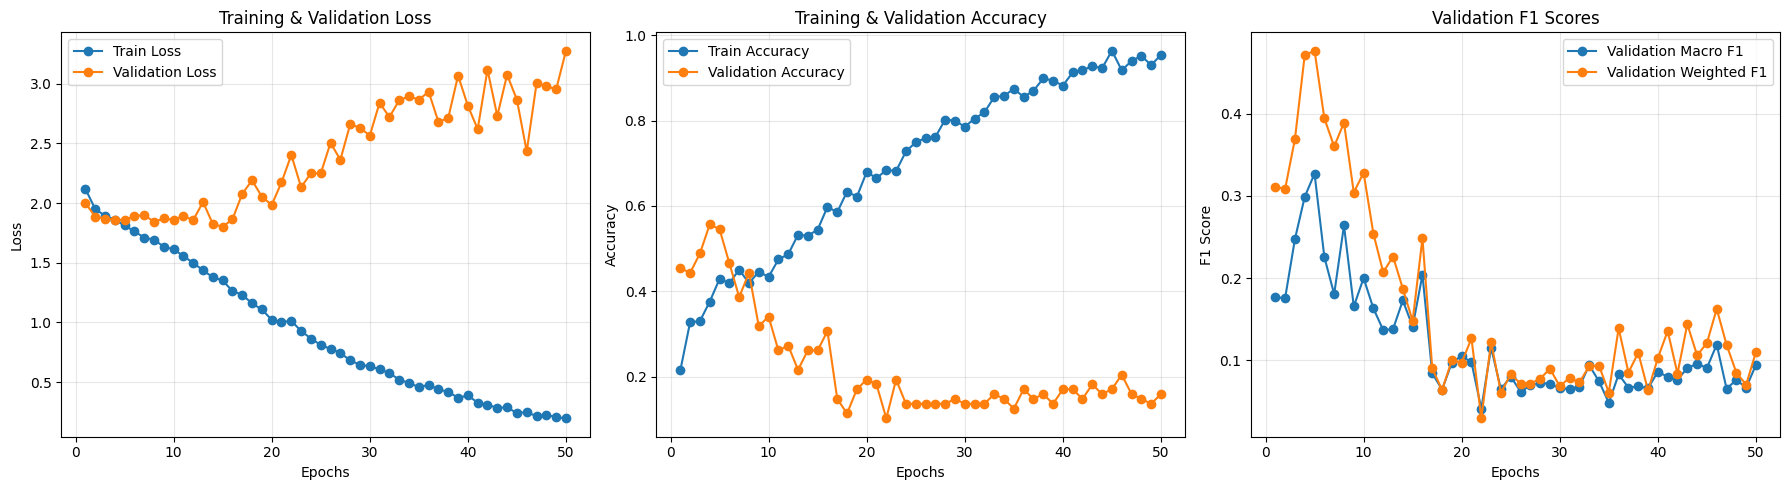

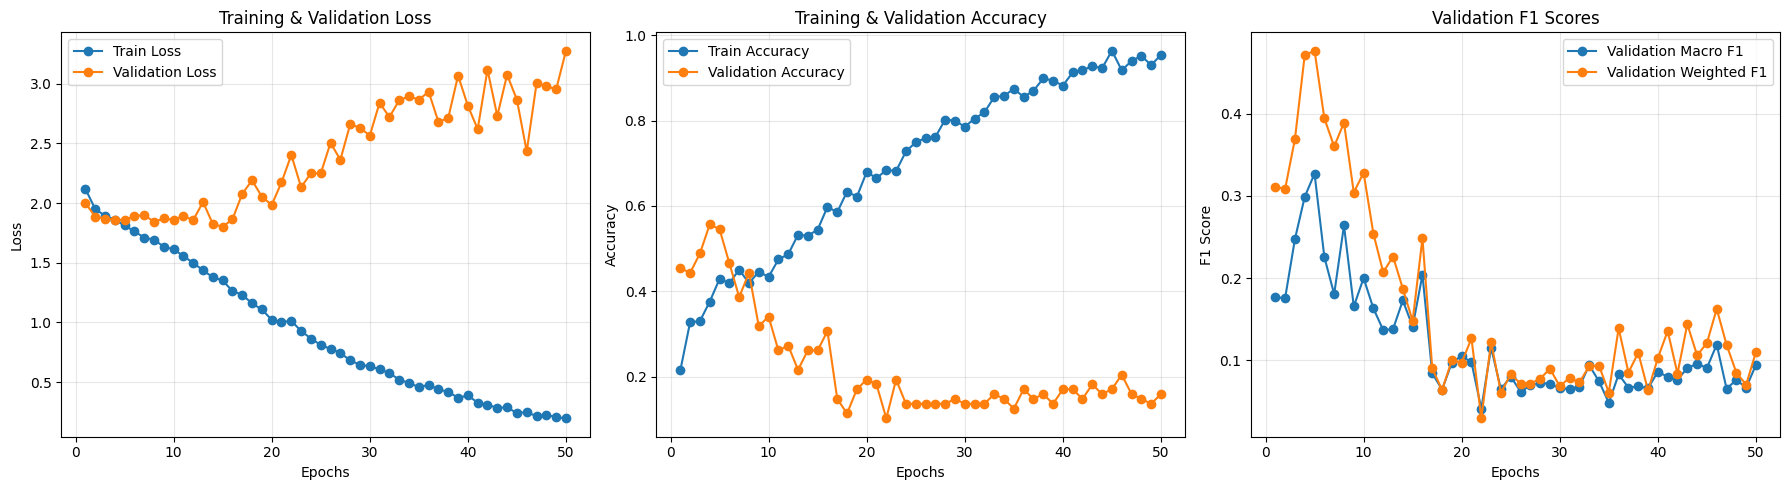

In [ ]:
plot_training_curves(
    train_losses=train_losses,
    val_losses=val_losses,
    train_accuracies=train_accuracies,
    val_accuracies=val_accuracies,
    val_macro_f1s=val_macro_f1s,
    val_weighted_f1s=val_weighted_f1s,
    save_path=REPO_ROOT / "reports" / "figures" / "training_curves.png",
)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model.load_state_dict(
    torch.load(checkpoint_path, map_location=device)
)

model.to(device)
model.eval()

print("Loaded checkpoint:", checkpoint_path)

Loaded checkpoint: /content/drive/MyDrive/EEG_Project_Github/eeg-brain-age/checkpoints/best_model.pth


\n===== Validation (best checkpoint) =====
Loss: 1.8596 | Accuracy: 0.5455
Macro F1: 0.3271 | Weighted F1: 0.4765
Macro Precision: 0.3100 | Macro Recall: 0.3543
\nPer-class report:
              precision    recall  f1-score   support

           0      0.604     0.821     0.696        39
           1      0.478     0.611     0.537        18
           2      0.333     0.250     0.286         4
           3      0.000     0.000     0.000         9
           4      0.000     0.000     0.000         9
           5      0.444     0.444     0.444         9

    accuracy                          0.545        88
   macro avg      0.310     0.354     0.327        88
weighted avg      0.426     0.545     0.476        88

Predicted distribution: {0: 53, 1: 23, 2: 3, 5: 9}
True distribution:      {0: 39, 1: 18, 2: 4, 3: 9, 4: 9, 5: 9}


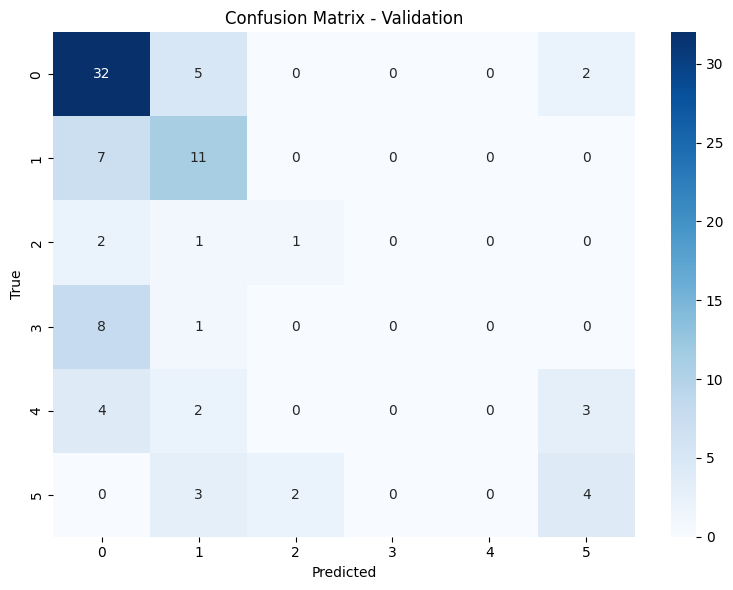

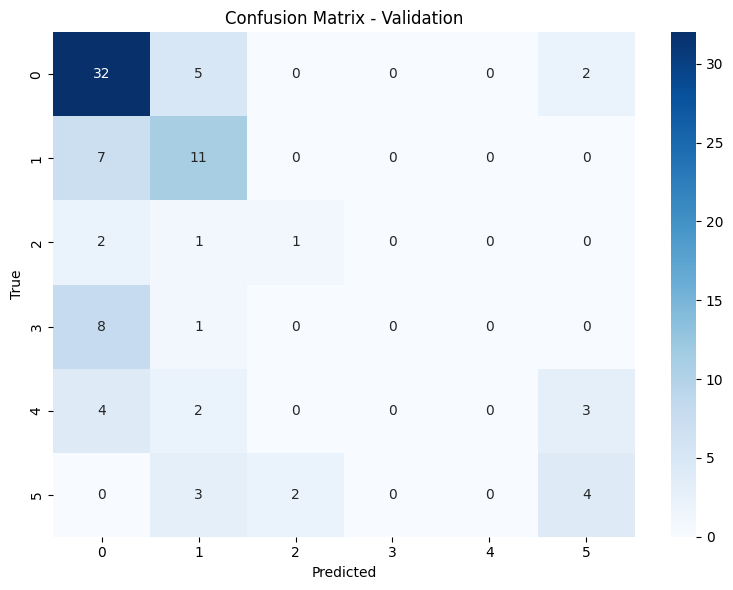

In [ ]:
val_results = evaluate_full(
    model,
    val_loader,
    criterion,
    title="Validation (best checkpoint)",
)

plot_confusion_matrix(
    val_results["confusion_matrix"],
    title="Confusion Matrix - Validation",
    save_path=(
        REPO_ROOT
        / "reports"
        / "figures"
        / "validation_confusion_matrix.png"
    ),
)

\n===== Test (best checkpoint) =====
Loss: 2.1002 | Accuracy: 0.3043
Macro F1: 0.0977 | Weighted F1: 0.2039
Macro Precision: 0.0753 | Macro Recall: 0.1429
\nPer-class report:
              precision    recall  f1-score   support

           0      0.397     0.833     0.538        30
           1      0.130     0.167     0.146        18
           2      0.000     0.000     0.000         9
           3      0.000     0.000     0.000         9
           4      0.000     0.000     0.000        12
           5      0.000     0.000     0.000        11
           7      0.000     0.000     0.000         3

    accuracy                          0.304        92
   macro avg      0.075     0.143     0.098        92
weighted avg      0.155     0.304     0.204        92

Predicted distribution: {0: 63, 1: 23, 2: 3, 5: 3}
True distribution:      {0: 30, 1: 18, 2: 9, 3: 9, 4: 12, 5: 11, 7: 3}


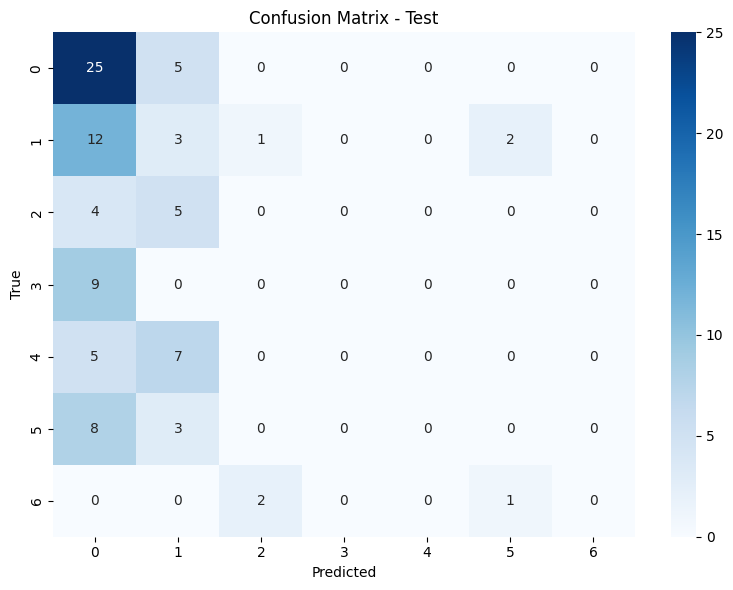

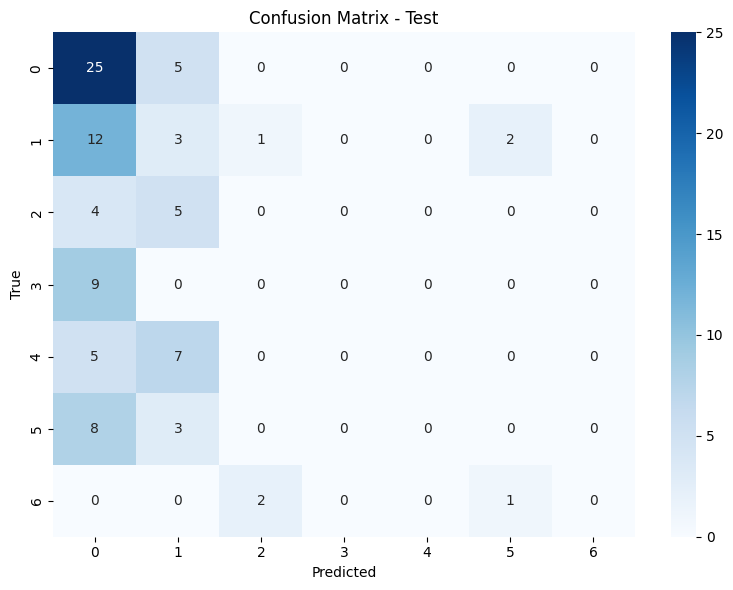

In [ ]:
test_results = evaluate_full(
    model,
    test_loader,
    criterion,
    title="Test (best checkpoint)",
)

plot_confusion_matrix(
    test_results["confusion_matrix"],
    title="Confusion Matrix - Test",
    save_path=(
        REPO_ROOT
        / "reports"
        / "figures"
        / "test_confusion_matrix.png"
    ),
)